# Vanilla VAE peak fitting on PROPHESY spectra

This notebook uses the 52,500-spectrum labeled PROPHESY ZIP with the same fully connected vanilla VAE encoder and decoder as the atmospheric notebook. A peak head predicts centers, Gaussian widths, and area fractions. Train a separate model for C 1s, S 2p, or O 1s because their energy grids differ. Run from the `spectraVAE` directory.


In [1]:
from pathlib import Path
import subprocess
import sys
import matplotlib.pyplot as plt
import numpy as np
from prophesy_peakfit.dataset import load_region
from prophesy_peakfit.vanilla_vae import fit_spectrum

ARCHIVE = Path('datasets/prophesy_peakfit.zip')
REGION = 'C1s'  # Change to 'S2p' or 'O1s' for a separate model.
EPOCHS = 100
data = load_region(ARCHIVE, REGION)
print(REGION, 'spectra:', len(data['noisy_counts']), 'points:', len(data['axis_eV']))
print(dict(zip(*np.unique(data['split'], return_counts=True))))


C1s spectra: 47020 points: 401
{np.str_('test'): np.int64(8175), np.str_('train'): np.int64(32200), np.str_('validation'): np.int64(6645)}


## Train

Training uses the ZIP directly. All scans and photon energies from one source workbook stay in the same split. The best validation checkpoint and peak predictions for the held-out spectra are saved under `outputs/prophesy_vanilla_vae/<region>/`.


In [2]:
command = [sys.executable, '-m', 'prophesy_peakfit.vanilla_vae',
           '--archive', str(ARCHIVE), '--region', REGION, '--epochs', str(EPOCHS)]
subprocess.run(command, check=True)


C1s epoch 001: validation=0.02779, center MAE=0.354 eV
C1s epoch 002: validation=0.01107, center MAE=0.199 eV
C1s epoch 003: validation=0.00783, center MAE=0.129 eV
C1s epoch 004: validation=0.00585, center MAE=0.080 eV
C1s epoch 005: validation=0.00523, center MAE=0.091 eV
C1s epoch 006: validation=0.00433, center MAE=0.056 eV
C1s epoch 007: validation=0.00410, center MAE=0.062 eV
C1s epoch 008: validation=0.00373, center MAE=0.059 eV
C1s epoch 009: validation=0.00363, center MAE=0.050 eV
C1s epoch 010: validation=0.00336, center MAE=0.047 eV
C1s epoch 011: validation=0.00315, center MAE=0.043 eV
C1s epoch 012: validation=0.00300, center MAE=0.040 eV
C1s epoch 013: validation=0.00293, center MAE=0.041 eV
C1s epoch 014: validation=0.00283, center MAE=0.047 eV
C1s epoch 015: validation=0.00275, center MAE=0.036 eV
C1s epoch 016: validation=0.00266, center MAE=0.036 eV
C1s epoch 017: validation=0.00256, center MAE=0.033 eV
C1s epoch 018: validation=0.00253, center MAE=0.046 eV
C1s epoch 

CompletedProcess(args=['/home/umar/anaconda3/envs/VAE/bin/python', '-m', 'prophesy_peakfit.vanilla_vae', '--archive', 'datasets/prophesy_peakfit.zip', '--region', 'C1s', '--epochs', '100'], returncode=0)

## Inspect one held-out peak fit

The red lines are the generating peak centers; the blue lines are the model's predicted centers. The model's clean spectrum is a denoised reconstruction of the simulated peak signal.


8175


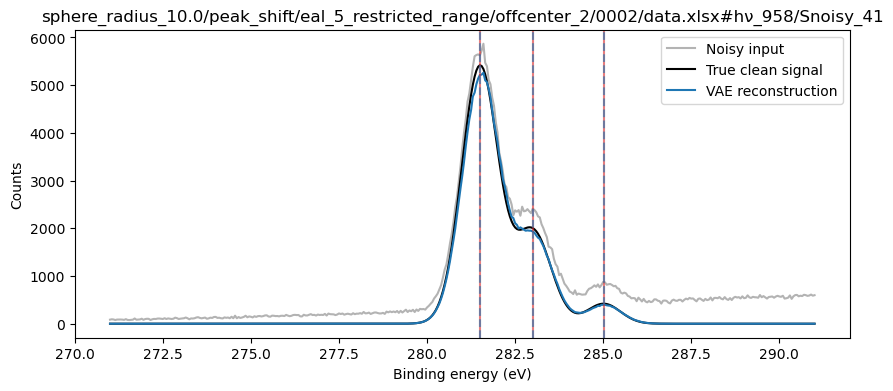

Predicted centers (eV): [281.5048  283.00986 285.01135]
Predicted Gaussian sigma (eV): [0.5059952  0.50597817 0.46213508]
Predicted peak areas (counts eV): [6848.3823  2464.1646   488.23648]


In [20]:
test_index = np.flatnonzero(data['split'] == 'test')[8160]
print(len(np.flatnonzero(data['split'] == 'test')))
checkpoint = Path('outputs/prophesy_vanilla_vae') / REGION / 'best.pt'
fit = fit_spectrum(checkpoint, data['noisy_counts'][test_index])
axis = data['axis_eV']
fig, ax = plt.subplots(figsize=(10, 4))
ax.plot(axis, data['noisy_counts'][test_index], color='0.7', label='Noisy input')
ax.plot(axis, data['clean_counts'][test_index], color='black', label='True clean signal')
ax.plot(axis, fit['clean_counts'], color='tab:blue', label='VAE reconstruction')
for center in data['peak_center_eV'][test_index]:
    ax.axvline(center, color='tab:red', alpha=0.6)
for center in fit['center_eV']:
    ax.axvline(center, color='tab:blue', linestyle='--', alpha=0.6)
ax.set(xlabel='Binding energy (eV)', ylabel='Counts', title=data['sample_id'][test_index])
ax.legend()
plt.show()
print('Predicted centers (eV):', fit['center_eV'])
print('Predicted Gaussian sigma (eV):', fit['sigma_eV'])
print('Predicted peak areas (counts eV):', fit['area_counts_eV'])
